# CivicAI - 05 Improving the stacking model (Phase 6b)

Phase 6 built a stacking classifier that did **not** beat XGBoost alone. This notebook tries to improve the stack, and tests the result on **new data that no model has been scored on**.

1. Rules, the selection rule and the success criterion (written before anything is run)
2. A fresh forward test set
3. The base models and their out-of-fold predictions
4. Diagnosis: is the gap to XGBoost mostly the decision threshold?
5. The experiments
6. The winner, and whether the success criterion is met
7. Refitting and saving the winner
8. *(added after sections 1-7 are committed)* Scoring the forward test set, once

## 1. Rules, fixed before anything is run

**The old test split is used up.** It was scored once in Phase 6, so its numbers have been seen. From now on it is never used to choose anything. Its Phase 6 results stay as they are in `reports/test_results.csv` ("test v1, already seen"). The Phase 6 model is frozen as git tag `phase6-v1` and `models/model_v1.joblib`.

**Where each decision is made**

| Decision | Made on |
| --- | --- |
| Fitting every model | training split only |
| The decision threshold (cut-off) of a stack | **training** out-of-fold predictions, never the validation split |
| Which experiment wins | validation split |
| The honest final score | the new forward test set, scored once at the very end |

**Selection rule.** At most 8 experiments are run. Each is a stack with a cut-off chosen on the training out-of-fold predictions. The winner is the experiment with the highest **validation macro F1**; ties are broken by validation ROC-AUC. An experiment can only win if its model file is under about 30 MB and one prediction takes under about 150 ms.

**How the experiments depend on each other** (also fixed in advance):

- (a) and (b) are the Phase 6 stack with the final estimator's `class_weight` set to `"balanced"` and to none. Whichever has the higher validation macro F1 sets the `class_weight` used in all later experiments.
- (c1), (c2), (c3) change the base models. The 0.97 correlation rule from Phase 5b is treated here as a rule of thumb, not a constraint, so Logistic Regression is allowed back in.
- (d) uses two XGBoost models of different depth plus the non-XGBoost members of the best experiment so far.
- (e) replaces the Logistic Regression final estimator with a small gradient boosting (100 trees of depth 2) on the base models of the best experiment so far.

**Success criterion.** The stack **at least equals XGBoost alone on validation macro F1, with ROC-AUC not lower.** "XGBoost alone" is the Phase 5 model as it would be deployed, at the usual cut-off of 0.5 (validation macro F1 0.8351, ROC-AUC 0.9433). Because the stacks get a tuned cut-off, XGBoost with a cut-off tuned in the same way is also shown, as the stricter comparison.

**If no experiment meets the criterion,** the best one is still deployed, because a stacking classifier is a course requirement, and the notebook says plainly that it did not beat XGBoost and why.

**A warning about the validation scores below.** Picking the best of several experiments on the validation split makes the winner's validation score a little optimistic. That is exactly why the forward test set exists.

In [1]:
import io
import json
import sys
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "..")                 # so that "src" can be imported from the notebooks folder
from src import features as ft
from src import preprocessing as pp
from src import train as tr

FIG_DIR = Path("../reports/figures")
BLUE, ORANGE, AQUA, GREY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#c3c2b7", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.grid": True, "grid.color": "#e8e7e3", "axes.axisbelow": True,
})
NAMES = {"xgboost": "XGBoost (depth 8)", "xgboost_shallow": "XGBoost (depth 4)", "logistic_regression": "Logistic Regression",
         "naive_bayes": "Bernoulli Naive Bayes", "random_forest": "Random Forest"}

X_train, y_train = tr.load_xy("train", "../data/processed")
X_val, y_val = tr.load_xy("val", "../data/processed")
best_settings = json.loads(Path("../reports/best_settings.json").read_text())
print(f"Training split  : {len(X_train):,} rows, class 0 share {1 - y_train.mean():.1%}")
print(f"Validation split: {len(X_val):,} rows, class 0 share {1 - y_val.mean():.1%}")

Training split  : 139,206 rows, class 0 share 17.2%
Validation split: 29,830 rows, class 0 share 16.8%


## 2. A fresh forward test set

**What it is.** Requests created **after** the last request of the old test split (2026-08-31), pulled from the same NYC Open Data table with the same script (`python src/fetch_data.py --start 2026-09-01 --end 2026-10-29 --name forward`): closed requests only, the same 1-in-48 sample by `unique_key`, four date windows per month. The last day included is 2026-10-28, which is 14 days before the pull, so every request has had at least two weeks to be closed and its 7-day label cannot change any more.

**Same cleaning, same label rule.** `pp.clean_new_rows` runs the Phase 3 steps (types, text, ZIP, coordinates, target, dropping rows with a missing or negative duration). Nothing is learned from the new rows: the lists of common categories are the ones learned on the training split (`models/cleaning_values.json`).

**No model is scored on it in this section.** It is only described.

In [2]:
raw_forward = pd.read_parquet("../data/raw/nyc311_forward_raw.parquet")
values = pp.load_cleaning_values("../models/cleaning_values.json")       # learned on the training split
forward = pp.clean_new_rows(raw_forward, values)
forward.to_parquet("../data/processed/test_forward.parquet", index=False)

old_test_end = pd.Timestamp(json.loads(Path("../models/model_meta.json").read_text())["split"]["test"]["to"])
train = pd.read_parquet("../data/processed/train.parquet")
assert forward["created_date"].min() > old_test_end and forward["unique_key"].is_unique
assert not set(forward["unique_key"]) & set(pd.read_parquet("../data/processed/clean.parquet", columns=["unique_key"])["unique_key"])

print(f"Raw rows pulled        : {len(raw_forward):,}")
print(f"Usable rows after cleaning: {len(forward):,}  (dropped {len(raw_forward) - len(forward):,} with a missing or negative duration)")
print(f"Created from {forward['created_date'].min()} to {forward['created_date'].max()}  (old test split ended {old_test_end})")
print(f"No request is shared with the original data. Saved ../data/processed/test_forward.parquet")
assert len(forward) >= 10_000, "fewer than 10,000 usable rows: stop and ask"

balance = pd.DataFrame({
    "rows": [len(train), len(X_val), 29831, len(forward)],
    "class 0 share (not resolved within 7 days)": [1 - train[ft.TARGET].mean(), 1 - y_val.mean(), 0.1833, 1 - forward[ft.TARGET].mean()],
}, index=["training", "validation", "old test (from Phase 6 results)", "forward test"])
display(balance.style.format({"rows": "{:,}", "class 0 share (not resolved within 7 days)": "{:.1%}"}))
by_month = forward.groupby(forward["created_date"].dt.to_period("M"))[ft.TARGET].agg(rows="size", class0_share=lambda s: 1 - s.mean())
display(by_month.style.format({"rows": "{:,}", "class0_share": "{:.1%}"}))

Raw rows pulled        : 12,076
Usable rows after cleaning: 12,069  (dropped 7 with a missing or negative duration)
Created from 2026-09-01 00:03:23 to 2026-10-28 23:59:06  (old test split ended 2026-08-31 23:59:06)
No request is shared with the original data. Saved ../data/processed/test_forward.parquet


,rows,class 0 share (not resolved within 7 days)
training,"139,206",17.2%
validation,"29,830",16.8%
old test (from Phase 6 results),"29,831",18.3%
forward test,"12,069",15.5%


,rows,class0_share
created_date,,
2026-09,"6,271",17.4%
2026-10,"5,798",13.5%


### A caveat: requests that are still open

The sample contains **closed** requests only, as the original data did. For old requests that hardly matters: by the time the original data was pulled, 98.0% of the requests from 2024-01 to 2026-08 were closed. The forward period is recent, so more of its requests are still open, and **every request that is still open after 14 days is, by definition, a class 0 request** (not resolved within 7 days). Leaving them out makes the forward set look a little easier than reality.

To measure how much this matters, the still-open requests of the same period are pulled with the same 1-in-48 rule and kept in a **separate** file with the label 0. The main forward test set stays "closed requests only", so that it is built exactly like the training, validation and old test data. The separate file is used once in section 8, for a sensitivity check.

In [3]:
status = pd.read_csv("../data/raw/status_counts_forward.csv")
display(status.style.format({"n": "{:,}", "share_pct": "{:.2f}%"}).hide(axis="index"))
not_closed_share = 1 - status.loc[status["status"] == "Closed", "n"].sum() / status["n"].sum()
print(f"Not closed in the forward period: {not_closed_share:.1%} of all requests (in the original period: 2.0%)")

open_file = Path("../data/raw/nyc311_forward_open_raw.csv")
if not open_file.exists():                                        # one small API call, saved so it is not repeated
    sys.path.append("../src")
    from fetch_data import BASE_URL, SAMPLE_FILTER, get
    params = {"$where": "status != 'Closed' AND created_date >= '2026-09-01T00:00:00' AND created_date < '2026-10-29T00:00:00' "
                        f"AND closed_date IS NULL AND {SAMPLE_FILTER}",
              "$order": "unique_key", "$limit": 50000}
    open_file.write_text(get(BASE_URL + ".csv", params), encoding="utf-8", newline="")
raw_open = pd.read_csv(open_file, dtype=str, keep_default_na=False, na_values=[""])
still_open = pp.apply_rare_categories(pp.clean_features(pp.convert_dates(raw_open)), values)
still_open[ft.TARGET] = 0                                         # open for more than 14 days = not resolved within 7 days
still_open = still_open[["unique_key", "created_date"] + pp.CATEGORICAL_COLUMNS + ["latitude", "longitude", ft.TARGET]]
still_open.to_parquet("../data/processed/test_forward_open.parquet", index=False)

with_open = pd.concat([forward[ft.TARGET], still_open[ft.TARGET]])
print(f"Still-open requests in the 1-in-48 sample: {len(still_open):,} (statuses: {raw_open['status'].value_counts().to_dict()})")
print(f"Class 0 share, closed requests only (the forward test set): {1 - forward[ft.TARGET].mean():.1%}")
print(f"Class 0 share if the still-open requests are added         : {1 - with_open.mean():.1%}  ({len(with_open):,} rows)")
print("Largest complaint types among the still-open requests:", still_open["complaint_type"].value_counts().head(5).to_dict())

status,n,share_pct
Closed,"578,782",90.82%
In Progress,"31,644",4.97%
Open,"23,905",3.75%
Assigned,"2,657",0.42%
Pending,218,0.03%
Unspecified,49,0.01%


Not closed in the forward period: 9.2% of all requests (in the original period: 2.0%)


Still-open requests in the 1-in-48 sample: 1,024 (statuses: {'In Progress': 613, 'Open': 392, 'Assigned': 15, 'Pending': 3, 'Unspecified': 1})
Class 0 share, closed requests only (the forward test set): 15.5%
Class 0 share if the still-open requests are added         : 22.1%  (13,093 rows)
Largest complaint types among the still-open requests: {'OVERGROWN TREE/BRANCHES': 106, 'UNSANITARY CONDITION': 69, 'FOR HIRE VEHICLE COMPLAINT': 62, 'Other': 58, 'DAMAGED TREE': 55}


### Is the complaint-type mix like the training data?

Shares of each complaint type in the training split and in the forward test set. The last line is one number for the whole comparison: the share of requests that would have to change type for the two mixes to be equal (0% = identical mix).

In [4]:
mix = pd.DataFrame({"training share": train["complaint_type"].value_counts(normalize=True),
                    "forward share": forward["complaint_type"].value_counts(normalize=True)}).fillna(0)
mix["difference (points)"] = (mix["forward share"] - mix["training share"]) * 100
rate = pd.DataFrame({"training: resolved within 7d": train.groupby("complaint_type")[ft.TARGET].mean(),
                     "forward: resolved within 7d": forward.groupby("complaint_type")[ft.TARGET].mean()})
mix = mix.join(rate)
fmt = {"training share": "{:.1%}", "forward share": "{:.1%}", "difference (points)": "{:+.1f}",
       "training: resolved within 7d": "{:.1%}", "forward: resolved within 7d": "{:.1%}"}
print("The 12 most common complaint types in the training split")
display(mix.sort_values("training share", ascending=False).head(12).style.format(fmt, na_rep="-"))
print("The 8 largest changes in share")
display(mix.reindex(mix["difference (points)"].abs().sort_values(ascending=False).index).head(8).style.format(fmt, na_rep="-"))

distance = mix["difference (points)"].abs().sum() / 2
val_mix = pd.read_parquet("../data/processed/val.parquet")["complaint_type"].value_counts(normalize=True)
val_distance = (mix["training share"].sub(val_mix, fill_value=0).abs().sum()) * 100 / 2
print(f"Mix difference, training vs forward test: {distance:.1f}% of requests would have to change type")
print(f"For comparison, training vs validation   : {val_distance:.1f}%")
print(f"Requests whose complaint type is 'Other' (rare or new since training): training {mix.loc['Other', 'training share']:.2%}, "
      f"forward {mix.loc['Other', 'forward share']:.2%}")

The 12 most common complaint types in the training split


,training share,forward share,difference (points),training: resolved within 7d,forward: resolved within 7d
complaint_type,,,,,
ILLEGAL PARKING,15.6%,18.5%,+2.9,100.0%,100.0%
NOISE - RESIDENTIAL,11.8%,10.8%,-1.1,100.0%,100.0%
HEAT/HOT WATER,7.7%,4.5%,-3.2,99.8%,100.0%
NOISE - STREET/SIDEWALK,5.0%,5.8%,+0.8,100.0%,100.0%
BLOCKED DRIVEWAY,5.0%,5.6%,+0.7,100.0%,100.0%
UNSANITARY CONDITION,3.4%,4.1%,+0.7,39.2%,41.4%
WATER SYSTEM,2.0%,0.0%,-2.0,88.4%,-
ABANDONED VEHICLE,2.0%,1.9%,-0.1,100.0%,100.0%
PLUMBING,2.0%,2.0%,+0.0,46.3%,42.7%


The 8 largest changes in share


,training share,forward share,difference (points),training: resolved within 7d,forward: resolved within 7d
complaint_type,,,,,
HEAT/HOT WATER,7.7%,4.5%,-3.2,99.8%,100.0%
ILLEGAL PARKING,15.6%,18.5%,+2.9,100.0%,100.0%
Other,0.5%,3.1%,+2.5,60.0%,82.4%
WATER SYSTEM,2.0%,0.0%,-2.0,88.4%,-
NOISE - RESIDENTIAL,11.8%,10.8%,-1.1,100.0%,100.0%
NOISE - STREET/SIDEWALK,5.0%,5.8%,+0.8,100.0%,100.0%
SEWER,0.7%,0.0%,-0.7,92.8%,-
UNSANITARY CONDITION,3.4%,4.1%,+0.7,39.2%,41.4%


Mix difference, training vs forward test: 13.9% of requests would have to change type
For comparison, training vs validation   : 16.5%
Requests whose complaint type is 'Other' (rare or new since training): training 0.54%, forward 3.07%


**What the forward test set looks like.**

- **Size and dates.** 12,069 usable requests (12,076 pulled, 7 dropped for a missing or negative duration), created from 2026-09-01 to 2026-10-28. That is above the 10,000 rows needed to continue. None of them is in the original data.
- **Class balance.** 15.5% are class 0 (not resolved within 7 days), against 17.2% in training, 16.8% in validation and 18.3% in the old test split. September is 17.4% and October 13.5%.
- **Part of that low share is the still-open effect.** 9.2% of all requests in this period were not closed yet when the data was pulled, against 2.0% for the original period. Adding the 1,024 still-open requests of the sample as class 0 raises the class 0 share from 15.5% to 22.1%. October looks easier than September mainly because more of its slow requests are still open and therefore missing. **The forward test set is cleaner than the old test split (no model has seen it) but it is also somewhat easier than reality**, so section 8 reports both versions.
- **Complaint-type mix.** 13.9% of requests would have to change type to match the training mix. Training against validation is 16.5%, so this is a normal amount of change. Most of it is seasonal (fewer heat and hot water complaints in September and October, more illegal parking).
- **Two complaint types were renamed by the city.** `Water System` and `Sewer` stop at the end of July 2026 and do not appear in the forward period at all; `Water Maintenance` (189 requests) and `Sewer Maintenance` (93) take their place. These names were too rare in the training period to be kept, so the model sees them as `Other`. The share of `Other` rises from 0.5% in training to 3.1% here. This is a real change in the data that the model cannot know about, and a fair test of how it copes.

## 3. The base models and their out-of-fold predictions

Every experiment is a stack over some of these five base models. Four are the tuned models of Phase 5; the fifth is a shallower XGBoost (depth 4, a setting from the Phase 5 list) for experiment (d).

For each base model two things are computed once and reused by all experiments:

- its **out-of-fold probabilities for the training rows** (5 stratified folds, the same folds as inside a `StackingClassifier`), which is what a final estimator learns from;
- its **probabilities for the validation rows**, from the model fitted on the whole training split.

Phase 6 showed that a final estimator fitted on these out-of-fold probabilities is identical to the one a real `StackingClassifier` fits (differences of 1e-13), so the experiments can be run this way without fitting a full stack each time. The winner is fitted as a real pipeline in section 7 and checked against its experiment row.

In [5]:
cleaner = ft.RequestCleaner(features=list(ft.FINAL_FEATURES)).fit(X_train)
Xc_train, Xc_val = cleaner.transform(X_train), cleaner.transform(X_val)
library = tr.base_library(best_settings)
one_clean = Xc_val.iloc[[0]]

def median_ms(call, repeats=30):
    call()
    times = []
    for _ in range(repeats):
        start = time.perf_counter()
        call()
        times.append((time.perf_counter() - start) * 1000)
    return float(np.median(times))

oof_train, base_val, base_fitted, rows = {}, {}, {}, []
start_all = time.time()
for key, (name, settings) in library.items():
    start = time.time()
    oof_train[key] = tr.cross_val_predict(tr.make_base_pipeline(name, settings), Xc_train, y_train,
                                          cv=tr.stack_folds(), method="predict_proba")[:, 1]
    base_fitted[key] = tr.make_base_pipeline(name, settings).fit(Xc_train, y_train)
    base_val[key] = base_fitted[key].predict_proba(Xc_val)[:, 1]
    buffer = io.BytesIO()
    joblib.dump(base_fitted[key], buffer)
    rows.append({"base model": NAMES[key], "key": key,
                 "macro F1 out-of-fold (train)": tr.evaluate_probability(y_train, oof_train[key])["macro_f1"],
                 "macro F1 validation": tr.evaluate_probability(y_val, base_val[key])["macro_f1"],
                 "ROC-AUC out-of-fold (train)": tr.evaluate_probability(y_train, oof_train[key])["roc_auc"],
                 "ROC-AUC validation": tr.evaluate_probability(y_val, base_val[key])["roc_auc"],
                 "file MB": len(buffer.getvalue()) / 1e6,
                 "one prediction ms": median_ms(lambda: base_fitted[key].predict_proba(one_clean)),
                 "seconds": time.time() - start})
oof_train, base_val = pd.DataFrame(oof_train), pd.DataFrame(base_val)
base_table = pd.DataFrame(rows).set_index("base model")
clean_ms = median_ms(lambda: cleaner.transform(X_val.iloc[[0]]))
print(f"All base models: {time.time() - start_all:.0f} s. Cleaning one request takes {clean_ms:.1f} ms.")
display(base_table.drop(columns="key").style.format({c: "{:.4f}" for c in base_table.columns if "F1" in c or "AUC" in c})
        .format({"file MB": "{:.2f}", "one prediction ms": "{:.1f}", "seconds": "{:.0f}"}))
print("Correlation of the base models' validation probabilities")
display(base_val.rename(columns=NAMES).corr().style.format("{:.3f}"))

All base models: 181 s. Cleaning one request takes 44.0 ms.


,macro F1 out-of-fold (train),macro F1 validation,ROC-AUC out-of-fold (train),ROC-AUC validation,file MB,one prediction ms,seconds
base model,,,,,,,
XGBoost (depth 8),0.836865,0.835118,0.955419,0.943290,1.80,12.4,40
XGBoost (depth 4),0.832269,0.832335,0.950634,0.941248,0.42,11.7,17
Logistic Regression,0.812599,0.815037,0.951316,0.941354,0.02,11.0,11
Bernoulli Naive Bayes,0.813776,0.809334,0.944124,0.937731,0.04,13.8,5
Random Forest,0.799858,0.789189,0.948799,0.940841,17.94,46.9,107


Correlation of the base models' validation probabilities


,XGBoost (depth 8),XGBoost (depth 4),Logistic Regression,Bernoulli Naive Bayes,Random Forest
XGBoost (depth 8),1.000,0.987,0.975,0.951,0.951
XGBoost (depth 4),0.987,1.000,0.984,0.950,0.978
Logistic Regression,0.975,0.984,1.000,0.954,0.975
Bernoulli Naive Bayes,0.951,0.950,0.954,1.000,0.925
Random Forest,0.951,0.978,0.975,0.925,1.000


## 4. Diagnosis: is the gap mostly the decision threshold?

In Phase 6 the stack and XGBoost ranked requests equally well (the same ROC-AUC) but the stack had a lower macro F1. Macro F1 depends on the **cut-off**: the probability at or above which a request is called "resolved within 7 days". Both models used 0.5. If the two models simply sit at different points of the same trade-off, moving the cut-off should close the gap.

The chart shows macro F1 for every cut-off from 0.05 to 0.95, for the Phase 6 stack (v1) and for XGBoost alone:

- on the **training** rows, using out-of-fold predictions (this is where a cut-off may be chosen),
- on the **validation** rows (shown for the diagnosis only; no cut-off is chosen here).

The probabilities reproduce the Phase 6 validation scores of the v1 stack and of XGBoost exactly.


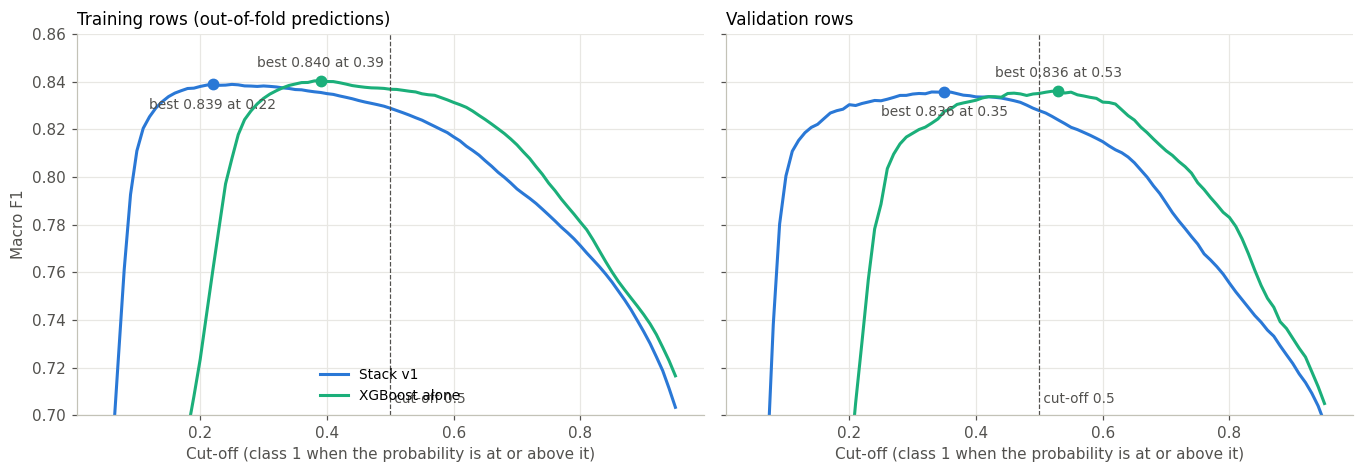

,validation macro F1 at 0.5,cut-off chosen on training,validation macro F1 at that cut-off,best cut-off on validation (not usable),validation macro F1 at its best,validation ROC-AUC
model,,,,,,
Stack v1,0.8279,0.22,0.8309,0.35,0.8358,0.9429
XGBoost alone,0.8351,0.39,0.8317,0.53,0.8361,0.9433


Stack v1 minus XGBoost, validation macro F1, in points:
  both at the cut-off 0.5                      : -0.73
  each at the cut-off chosen on training rows  : -0.08
  each at its own best cut-off on validation   : -0.03


In [6]:
V1_MEMBERS = ["xgboost", "naive_bayes", "random_forest"]
v1_final = {"type": "logistic", **best_settings[tr.STACK_FINAL_KEY]}
v1_meta = tr.make_meta(v1_final).fit(oof_train[V1_MEMBERS], y_train)
curves = {
    "Stack v1": {"train": tr.meta_out_of_fold(v1_final, oof_train[V1_MEMBERS], y_train), "val": v1_meta.predict_proba(base_val[V1_MEMBERS])[:, 1]},
    "XGBoost alone": {"train": oof_train["xgboost"].values, "val": base_val["xgboost"].values},
}
saved_v1 = pd.read_csv("../reports/stacking_validation.csv").set_index("model")
assert abs(tr.evaluate_probability(y_val, curves["Stack v1"]["val"])["macro_f1"] - saved_v1.loc["Stack", "macro_f1"]) < 1e-9
assert abs(tr.evaluate_probability(y_val, curves["XGBoost alone"]["val"])["macro_f1"] - saved_v1.loc["XGBoost", "macro_f1"]) < 1e-9
print("The probabilities reproduce the Phase 6 validation scores of the v1 stack and of XGBoost exactly.")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4), sharey=True)
diagnosis = []
for ax, split, y_true, title in [(axes[0], "train", y_train, "Training rows (out-of-fold predictions)"), (axes[1], "val", y_val, "Validation rows")]:
    for name, color in [("Stack v1", BLUE), ("XGBoost alone", AQUA)]:
        curve = tr.macro_f1_by_threshold(y_true, curves[name][split])
        ax.plot(curve.index, curve.values, color=color, linewidth=2, label=name)
        ax.scatter([curve.idxmax()], [curve.max()], color=color, s=45, zorder=3)
        ax.annotate(f"best {curve.max():.3f} at {curve.idxmax():.2f}", (curve.idxmax(), curve.max()), textcoords="offset points",
                    xytext=(0, 9 if name == "XGBoost alone" else -16), ha="center", fontsize=9, color=INK)
    ax.axvline(0.5, color=INK, linewidth=0.8, linestyle="--")
    ax.text(0.5, 0.705, " cut-off 0.5", color=INK, fontsize=9)
    ax.set_ylim(0.70, 0.86)
    ax.set_xlabel("Cut-off (class 1 when the probability is at or above it)")
    ax.set_title(title, loc="left", fontsize=11)
axes[0].set_ylabel("Macro F1")
axes[0].legend(loc="lower center", frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "07_macro_f1_by_threshold.png")
plt.show()

rows = []
for name in curves:
    train_curve = tr.macro_f1_by_threshold(y_train, curves[name]["train"])
    val_curve = tr.macro_f1_by_threshold(y_val, curves[name]["val"])
    chosen = float(train_curve.idxmax())
    rows.append({"model": name, "validation macro F1 at 0.5": val_curve[0.5],
                 "cut-off chosen on training": chosen, "validation macro F1 at that cut-off": val_curve[chosen],
                 "best cut-off on validation (not usable)": float(val_curve.idxmax()), "validation macro F1 at its best": val_curve.max(),
                 "validation ROC-AUC": tr.evaluate_probability(y_val, curves[name]["val"])["roc_auc"]})
diagnosis = pd.DataFrame(rows).set_index("model")
display(diagnosis.style.format("{:.4f}").format("{:.2f}", subset=["cut-off chosen on training", "best cut-off on validation (not usable)"]))
gap = lambda column: (diagnosis.loc["Stack v1", column] - diagnosis.loc["XGBoost alone", column]) * 100
print(f"Stack v1 minus XGBoost, validation macro F1, in points:")
print(f"  both at the cut-off 0.5                      : {gap('validation macro F1 at 0.5'):+.2f}")
print(f"  each at the cut-off chosen on training rows  : {gap('validation macro F1 at that cut-off'):+.2f}")
print(f"  each at its own best cut-off on validation   : {gap('validation macro F1 at its best'):+.2f}")
xgb_tuned_threshold = float(diagnosis.loc["XGBoost alone", "cut-off chosen on training"])
xgb_tuned = tr.evaluate_probability(y_val, base_val["xgboost"], xgb_tuned_threshold)

**Yes: the macro F1 gap in Phase 6 was almost entirely the decision threshold.**

- At the cut-off 0.5 the v1 stack is **0.73 points** below XGBoost on validation macro F1 (0.8279 against 0.8351).
- With each model at the cut-off chosen on its training out-of-fold predictions, the gap is **0.08 points** (0.8309 against 0.8317).
- With each model at its own best cut-off on the validation split (which could not be used in practice), the gap is **0.03 points**: both reach 0.836.
- ROC-AUC, which does not depend on a cut-off, was already the same (0.9429 against 0.9433).

So the two models have the **same ceiling**. The v1 stack only looked worse because its final estimator used class weights, which pushed its probabilities down and made 0.5 a poor cut-off for it (its best is around 0.2 to 0.35), while 0.5 happens to suit XGBoost (its validation optimum is 0.53).

**A caution that matters for the experiments.** A cut-off chosen on the training rows does not transfer perfectly. For XGBoost it picks 0.39, and that *lowers* its validation macro F1 from 0.8351 to 0.8317. The curves are flat near the top, and the out-of-fold predictions come from shuffled folds, so the best cut-off on the training rows sits a little lower than the best cut-off on later data. Tuning the cut-off removes the big gap, but it cannot be expected to add more than a few tenths of a point.

## 5. The experiments

Seven experiments are run (the limit was eight), in the order fixed in section 1. For each one:

1. the final estimator is fitted on the base models' out-of-fold probabilities for the **training** split;
2. the cut-off is the one with the highest macro F1 on the stack's own out-of-fold predictions for the **training** split;
3. the stack is scored on the **validation** split at that cut-off.

Every experiment is written to `reports/stacking_experiments.csv`, including any that fail or break a limit. The model file size is the sum of the base models' saved sizes; the time for one prediction is the cleaning step plus the base models (measured in section 3) plus the final estimator.

In [7]:
SIZE_LIMIT_MB, TIME_LIMIT_MS = 30, 150
experiments, probabilities = [], {}

def run(label, description, members, final):
    row = {"experiment": label, "description": description, "members": " + ".join(members),
           "final_estimator": json.dumps(final), "status": "ok", "note": ""}
    try:
        result, probabilities[label] = tr.run_stack_experiment(members, final, oof_train, y_train, base_val, y_val)
        meta = tr.make_meta(final).fit(oof_train[list(members)], y_train)
        meta_ms = median_ms(lambda: meta.predict_proba(base_val[list(members)].iloc[[0]]))
        row.update(result)
        row["file_mb"] = base_table.set_index("key").loc[list(members), "file MB"].sum()
        row["predict_one_ms"] = clean_ms + base_table.set_index("key").loc[list(members), "one prediction ms"].sum() + meta_ms
        row["within_limits"] = bool(row["file_mb"] < SIZE_LIMIT_MB and row["predict_one_ms"] < TIME_LIMIT_MS)
        if hasattr(meta, "coef_"):
            row["weights"] = json.dumps({k: round(float(w), 3) for k, w in zip(members, meta.coef_[0])})
    except Exception as error:                                   # a failed experiment is logged, not hidden
        row.update({"status": "failed", "note": f"{type(error).__name__}: {error}"[:200], "within_limits": False})
    experiments.append(row)
    return row

def best_so_far():
    ok = [e for e in experiments if e["status"] == "ok" and e["within_limits"]]
    return max(ok, key=lambda e: (e["macro_f1"], e["roc_auc"]))

LR = lambda class_weight: {"type": "logistic", "class_weight": class_weight, "C": 0.1}

a = run("a", "Phase 6 stack + cut-off chosen on training", V1_MEMBERS, LR("balanced"))
b = run("b", "Same, final estimator without class weights", V1_MEMBERS, LR(None))
class_weight = "balanced" if (a["macro_f1"], a["roc_auc"]) >= (b["macro_f1"], b["roc_auc"]) else None
print(f"(a) macro F1 {a['macro_f1']:.4f}, (b) macro F1 {b['macro_f1']:.4f} -> later experiments use class_weight = {class_weight}")

run("c1", "XGBoost + Logistic Regression + Naive Bayes", ["xgboost", "logistic_regression", "naive_bayes"], LR(class_weight))
run("c2", "XGBoost + Logistic Regression + Naive Bayes + Random Forest", ["xgboost", "logistic_regression", "naive_bayes", "random_forest"], LR(class_weight))
run("c3", "XGBoost + Logistic Regression", ["xgboost", "logistic_regression"], LR(class_weight))

others = [m for m in best_so_far()["members"].split(" + ") if not m.startswith("xgboost")]
print(f"Best so far: ({best_so_far()['experiment']}). Experiment (d) = two XGBoost models + {others}")
run("d", "XGBoost depth 8 + XGBoost depth 4 + the other members of the best so far", ["xgboost", "xgboost_shallow"] + others, LR(class_weight))

base_set = best_so_far()["members"].split(" + ")
print(f"Best so far: ({best_so_far()['experiment']}). Experiment (e) = gradient boosting final estimator on {base_set}")
run("e", "Small gradient boosting as final estimator, base models of the best so far", base_set, {"type": "gbm"})

log = pd.DataFrame(experiments)
log.to_csv("../reports/stacking_experiments.csv", index=False)
print(f"\nSaved ../reports/stacking_experiments.csv ({len(log)} experiments, {int((log['status'] != 'ok').sum())} failed)")

(a) macro F1 0.8309, (b) macro F1 0.8317 -> later experiments use class_weight = None


Best so far: (c2). Experiment (d) = two XGBoost models + ['logistic_regression', 'naive_bayes', 'random_forest']


Best so far: (c2). Experiment (e) = gradient boosting final estimator on ['xgboost', 'logistic_regression', 'naive_bayes', 'random_forest']



Saved ../reports/stacking_experiments.csv (7 experiments, 0 failed)


In [8]:
CLASS0 = ["precision_0", "recall_0", "f1_0"]
show = ["description", "threshold", "accuracy"] + CLASS0 + ["macro_f1", "roc_auc", "macro_f1_at_0.5", "file_mb", "predict_one_ms", "within_limits"]
reference = pd.DataFrame({
    "XGBoost alone, cut-off 0.5 (the success criterion)": {**tr.evaluate_probability(y_val, base_val["xgboost"]), "threshold": 0.5,
                                                           "description": "reference", "file_mb": base_table.set_index("key").loc["xgboost", "file MB"],
                                                           "predict_one_ms": clean_ms + base_table.set_index("key").loc["xgboost", "one prediction ms"]},
    f"XGBoost alone, cut-off {xgb_tuned_threshold:.2f} chosen on training": {**xgb_tuned, "threshold": xgb_tuned_threshold, "description": "reference (stricter)"},
    "Stack v1 as deployed in Phase 6 (cut-off 0.5)": {**tr.evaluate_probability(y_val, curves["Stack v1"]["val"]), "threshold": 0.5, "description": "reference"},
}).T
table = pd.concat([log.set_index("experiment"), reference])
number_format = {c: "{:.4f}" for c in ["accuracy", "macro_f1", "roc_auc", "macro_f1_at_0.5"] + CLASS0}
number_format.update({"threshold": "{:.2f}", "file_mb": "{:.1f}", "predict_one_ms": "{:.0f}"})
with pd.option_context("display.max_colwidth", None):
    display(table[show].style.format(number_format, na_rep="")
            .set_properties(subset=CLASS0, **{"background-color": "#fdebd8", "color": "black"})
            .set_properties(subset=["description"], **{"text-align": "left"})
            .highlight_max(subset=pd.IndexSlice[list(log["experiment"]), ["macro_f1", "roc_auc"]], props="font-weight: bold; text-decoration: underline"))
print("Weights of the Logistic Regression final estimators:")
for row in experiments:
    if row.get("weights"):
        print(f"  ({row['experiment']}) {row['weights']}")

,description,threshold,accuracy,precision_0,recall_0,f1_0,macro_f1,roc_auc,macro_f1_at_0.5,file_mb,predict_one_ms,within_limits
a,Phase 6 stack + cut-off chosen on training,0.22,0.9015,0.6868,0.7601,0.7216,0.8309,0.9429,0.8279,19.8,119,True
b,"Same, final estimator without class weights",0.60,0.9017,0.6858,0.7647,0.7231,0.8317,0.9431,0.8254,19.8,120,True
c1,XGBoost + Logistic Regression + Naive Bayes,0.59,0.9026,0.6921,0.7561,0.7227,0.8318,0.9436,0.8248,1.9,83,True
c2,XGBoost + Logistic Regression + Naive Bayes + Random Forest,0.61,0.9028,0.6876,0.7711,0.7270,0.8339,0.9434,0.8250,19.8,131,True
c3,XGBoost + Logistic Regression,0.57,0.9034,0.6943,0.7579,0.7247,0.8331,0.9437,0.8277,1.8,70,True
d,XGBoost depth 8 + XGBoost depth 4 + the other members of the best so far,0.61,0.9025,0.6860,0.7731,0.7269,0.8338,0.9434,0.8253,20.2,142,True
e,"Small gradient boosting as final estimator, base models of the best so far",0.59,0.9029,0.6952,0.7505,0.7218,0.8315,0.9429,0.8223,19.8,131,True
"XGBoost alone, cut-off 0.5 (the success criterion)",reference,0.50,0.8994,0.6620,0.8189,0.7321,0.8351,0.9433,,1.8,56,
"XGBoost alone, cut-off 0.39 chosen on training",reference (stricter),0.39,0.9026,0.6926,0.7549,0.7224,0.8317,0.9433,,,,
Stack v1 as deployed in Phase 6 (cut-off 0.5),reference,0.50,0.8896,0.6233,0.8656,0.7247,0.8279,0.9429,,,,


Weights of the Logistic Regression final estimators:
  (a) {"xgboost": 4.378, "naive_bayes": -1.267, "random_forest": 5.083}
  (b) {"xgboost": 5.218, "naive_bayes": -1.233, "random_forest": 3.794}
  (c1) {"xgboost": 5.022, "logistic_regression": 3.445, "naive_bayes": -1.224}
  (c2) {"xgboost": 4.517, "logistic_regression": 2.05, "naive_bayes": -1.541, "random_forest": 2.721}
  (c3) {"xgboost": 4.722, "logistic_regression": 2.265}
  (d) {"xgboost": 5.091, "xgboost_shallow": -1.251, "logistic_regression": 2.274, "naive_bayes": -1.491, "random_forest": 3.043}


## 6. The winner, and the success criterion

The selection rule from section 1 is applied by the code below: highest validation macro F1, then ROC-AUC, among the experiments within the size and time limits.

In [9]:
winner = best_so_far()
xgb_row = reference.loc["XGBoost alone, cut-off 0.5 (the success criterion)"]
print(f"Winner: experiment ({winner['experiment']}) - {winner['description']}")
print(f"  members {winner['members']}; final estimator {winner['final_estimator']}; cut-off {winner['threshold']:.2f}")
print(f"  validation macro F1 {winner['macro_f1']:.4f}, ROC-AUC {winner['roc_auc']:.4f}, "
      f"class 0 precision {winner['precision_0']:.4f}, class 0 recall {winner['recall_0']:.4f}")

f1_gap = (winner["macro_f1"] - xgb_row["macro_f1"]) * 100
auc_gap = (winner["roc_auc"] - xgb_row["roc_auc"]) * 100
criterion_met = bool(winner["macro_f1"] >= xgb_row["macro_f1"] and winner["roc_auc"] >= xgb_row["roc_auc"])
print(f"\nSuccess criterion (at least XGBoost alone at 0.5 on macro F1, ROC-AUC not lower):")
print(f"  macro F1 {winner['macro_f1']:.4f} vs {xgb_row['macro_f1']:.4f}  ({f1_gap:+.2f} points)")
print(f"  ROC-AUC  {winner['roc_auc']:.4f} vs {xgb_row['roc_auc']:.4f}  ({auc_gap:+.2f} points)")
print(f"  -> {'MET' if criterion_met else 'NOT MET'}")
print(f"Stricter comparison, XGBoost with its own cut-off chosen on training ({xgb_tuned_threshold:.2f}): "
      f"macro F1 {xgb_tuned['macro_f1']:.4f}  (winner {(winner['macro_f1'] - xgb_tuned['macro_f1']) * 100:+.2f} points)")

# How sure is the difference? 1,000 resamples of the validation requests (same rows for both models)
from sklearn.metrics import f1_score, roc_auc_score
rng = np.random.default_rng(42)
y_array, p_win, p_xgb = y_val.to_numpy(), probabilities[winner["experiment"]], base_val["xgboost"].to_numpy()
d_f1, d_f1_strict, d_auc = [], [], []
for _ in range(1000):
    pick = rng.integers(0, len(y_array), len(y_array))
    f1_win = f1_score(y_array[pick], p_win[pick] >= winner["threshold"], average="macro")
    d_f1.append(f1_win - f1_score(y_array[pick], p_xgb[pick] > 0.5, average="macro"))
    d_f1_strict.append(f1_win - f1_score(y_array[pick], p_xgb[pick] >= xgb_tuned_threshold, average="macro"))
    d_auc.append(roc_auc_score(y_array[pick], p_win[pick]) - roc_auc_score(y_array[pick], p_xgb[pick]))
for label, values in [("macro F1 vs XGBoost at 0.5", d_f1), (f"macro F1 vs XGBoost at {xgb_tuned_threshold:.2f}", d_f1_strict), ("ROC-AUC vs XGBoost", d_auc)]:
    low, high = np.percentile(values, [2.5, 97.5]) * 100
    print(f"  95% range of the difference, {label}: {low:+.2f} to {high:+.2f} points")

Winner: experiment (c2) - XGBoost + Logistic Regression + Naive Bayes + Random Forest
  members xgboost + logistic_regression + naive_bayes + random_forest; final estimator {"type": "logistic", "class_weight": null, "C": 0.1}; cut-off 0.61
  validation macro F1 0.8339, ROC-AUC 0.9434, class 0 precision 0.6876, class 0 recall 0.7711

Success criterion (at least XGBoost alone at 0.5 on macro F1, ROC-AUC not lower):
  macro F1 0.8339 vs 0.8351  (-0.12 points)
  ROC-AUC  0.9434 vs 0.9433  (+0.01 points)
  -> NOT MET
Stricter comparison, XGBoost with its own cut-off chosen on training (0.39): macro F1 0.8317  (winner +0.22 points)


  95% range of the difference, macro F1 vs XGBoost at 0.5: -0.40 to +0.15 points
  95% range of the difference, macro F1 vs XGBoost at 0.39: +0.03 to +0.44 points
  95% range of the difference, ROC-AUC vs XGBoost: -0.04 to +0.05 points


**Winner: experiment (c2)**, a stack of XGBoost, Logistic Regression, Bernoulli Naive Bayes and Random Forest, with a Logistic Regression final estimator without class weights and a cut-off of 0.61.

**The success criterion is NOT met.**

- Validation macro F1 is 0.8339 against 0.8351 for XGBoost alone: **0.12 points lower**. The 95% range of the difference, -0.40 to +0.15 points, includes zero, so the two are effectively level, but the criterion asked for "at least equal" and the stack is not.
- ROC-AUC is 0.9434 against 0.9433 (+0.01 points), so that half of the criterion holds.
- In the stricter comparison, where XGBoost also gets a cut-off chosen on the training rows (0.39), the stack is ahead by 0.22 points (0.8339 against 0.8317; range +0.03 to +0.44). XGBoost at 0.5 remains the better of the two XGBoost options on validation, so this does not rescue the criterion.

**Why no stack beat XGBoost.**

- All seven experiments landed between 0.8309 and 0.8339 macro F1 and between 0.9429 and 0.9437 ROC-AUC. Changing the base models, adding a second XGBoost, or using a gradient boosting final estimator moved the result by at most 0.3 points.
- The base models are too alike to add information: their validation probabilities are 0.93 to 0.99 correlated, and XGBoost is the strongest of them. Section 4 showed that the v1 stack and XGBoost have the same ceiling (0.836).
- The stack's cut-off is chosen on training rows and lands slightly off the validation optimum, while XGBoost's plain 0.5 happens to sit almost exactly on its optimum. That small piece of luck is about the size of the remaining difference.

**What did improve over the Phase 6 stack (v1).**

- Validation macro F1 rose from 0.8279 to 0.8339 (+0.60 points) and accuracy from 0.890 to 0.903.
- The balance of mistakes changed: precision of class 0 rose from 62.3% to 68.8%, and recall of class 0 fell from 86.6% to 77.1%. The v2 stack raises fewer false alarms and misses more slow requests. If catching slow requests matters more than avoiding false alarms, a lower cut-off can be used without retraining.
- The final estimator no longer uses class weights, so the probability the API returns is closer to a true probability.

**A smaller alternative.** Experiment (c3), XGBoost plus Logistic Regression only, scored 0.8331 (0.08 points below the winner) with a 1.8 MB file and about half the prediction time. The selection rule picks (c2), so (c2) is deployed; (c3) is noted in case size or speed on EC2 becomes a problem.

**Decision, as fixed in section 1:** the winner is deployed even though the criterion is not met, because a stacking classifier is a course requirement. The honest statement for the report is: *the improved stack matches XGBoost alone within the noise of the validation split, and does not beat it.* The validation scores above are slightly optimistic for the winner, because it was picked as the best of seven. Section 8 gives the clean number.

## 7. Refitting and saving the winner

The winner is now built as a real pipeline with `tr.build_stack_v2` and fitted on the **training split only**:

`clean` (the shared `RequestCleaner`) → `stack` (a `StackingClassifier` over the winner's base models, wrapped in scikit-learn's `FixedThresholdClassifier` so that `predict` uses the chosen cut-off; `predict_proba` is unchanged).

It is checked against its experiment row, saved as `models/model.joblib` (the Phase 6 model stays as `models/model_v1.joblib`), and the description files are refreshed. The five sample requests are the same validation rows as before, with the new model's answers. The fresh-process check is run again.

In [10]:
config = {"members": winner["members"].split(" + "), "final": json.loads(winner["final_estimator"]), "threshold": float(winner["threshold"])}
model = tr.build_stack_v2(best_settings, config)
fit_seconds = tr.fit_timed(model, X_train, y_train)
scores, val_probability = tr.evaluate(model, X_val, y_val)
print(f"Fitted on the training split in {fit_seconds:.0f} s: {config}")
print(f"Real pipeline, validation: macro F1 {scores['macro_f1']:.4f}, ROC-AUC {scores['roc_auc']:.4f}  "
      f"(experiment row: {winner['macro_f1']:.4f}, {winner['roc_auc']:.4f})")
print(f"Largest difference in validation probabilities against the experiment: {np.abs(val_probability - probabilities[winner['experiment']]).max():.2e}")
assert abs(scores["macro_f1"] - winner["macro_f1"]) < 1e-9 and abs(scores["roc_auc"] - winner["roc_auc"]) < 1e-9

best_settings[tr.STACK_V2_KEY] = config
Path("../reports/best_settings.json").write_text(json.dumps(best_settings, indent=2), encoding="utf-8")

v1_model = joblib.load("../models/model_v1.joblib")
scratch = joblib.load("../models/_validation_models.joblib")
validation_rows = {
    "Stack v2": scores,
    "Stack v1 (Phase 6)": tr.evaluate(v1_model, X_val, y_val)[0],
    "XGBoost alone": tr.evaluate(scratch["XGBoost alone"], X_val, y_val)[0],
    "Baseline: complaint type only": tr.evaluate(scratch["Baseline: complaint type only"], X_val, y_val)[0],
    "Baseline: majority class": tr.evaluate(scratch["Baseline: majority class"], X_val, y_val)[0],
}
v2_validation = pd.DataFrame(validation_rows).T
v2_validation.index.name = "model"
v2_validation.to_csv("../reports/stacking_v2_validation.csv")
display(v2_validation[["accuracy"] + CLASS0 + ["macro_f1", "roc_auc"]].style.format("{:.4f}")
        .set_properties(subset=CLASS0, **{"background-color": "#fdebd8", "color": "black", "font-weight": "bold"}))

joblib.dump(model, "../models/model.joblib")
size_mb = Path("../models/model.joblib").stat().st_size / 1e6
print(f"Saved ../models/model.joblib: {size_mb:.1f} MB (v1 is kept as model_v1.joblib). Saved ../reports/stacking_v2_validation.csv")

Fitted on the training split in 175 s: {'members': ['xgboost', 'logistic_regression', 'naive_bayes', 'random_forest'], 'final': {'type': 'logistic', 'class_weight': None, 'C': 0.1}, 'threshold': 0.61}
Real pipeline, validation: macro F1 0.8339, ROC-AUC 0.9434  (experiment row: 0.8339, 0.9434)
Largest difference in validation probabilities against the experiment: 2.22e-15


,accuracy,precision_0,recall_0,f1_0,macro_f1,roc_auc
model,,,,,,
Stack v2,0.9028,0.6876,0.7711,0.7270,0.8339,0.9434
Stack v1 (Phase 6),0.8896,0.6233,0.8656,0.7247,0.8279,0.9429
XGBoost alone,0.8994,0.6620,0.8189,0.7321,0.8351,0.9433
Baseline: complaint type only,0.8915,0.6866,0.6499,0.6678,0.8014,0.9377
Baseline: majority class,0.8321,0.0000,0.0000,0.0000,0.4542,0.5000


Saved ../models/model.joblib: 19.8 MB (v1 is kept as model_v1.joblib). Saved ../reports/stacking_v2_validation.csv


In [11]:
import copy, hashlib, subprocess
from datetime import datetime

MODEL_PATH = Path("../models/model.joblib")
sha256 = hashlib.sha256(MODEL_PATH.read_bytes()).hexdigest()

# Sample requests: the same five validation rows as before, with the new model's answers
samples = json.loads(Path("../data/sample_requests.json").read_text())
for item in samples["valid_requests"]:
    request = pd.DataFrame([item["request"]])
    probability = float(model.predict_proba(request)[0, 1])
    item["expected_probability_within_threshold"] = round(probability, 12)
    item["expected_predicted_class"] = int(model.predict(request)[0])
samples["decision_threshold"] = config["threshold"]
samples["description"] = ("Raw requests in the format of the API (CLAUDE.md section 6), with the answers of the v2 model. valid_requests come from the "
                          "VALIDATION split (no test split was used); the predicted class is 1 when the probability is at or above decision_threshold. "
                          "invalid_requests must be rejected by the API with the status shown.")
Path("../data/sample_requests.json").write_text(json.dumps(samples, indent=2), encoding="utf-8")
display(pd.DataFrame([{"example": v["name"], "complaint_type": v["request"]["complaint_type"], "true label": v["true_label"],
                       "probability within 7 days": v["expected_probability_within_threshold"], "predicted class": v["expected_predicted_class"]}
                      for v in samples["valid_requests"]]).style.format({"probability within 7 days": "{:.4f}"}).hide(axis="index"))

# Speed of one prediction from a raw request
one_request = pd.DataFrame([samples["valid_requests"][0]["request"]])
latency_ms = tr.predict_one_ms(model, one_request, repeats=60)
single = copy.deepcopy(model)
for name, estimator in ft.get_stack(single).named_estimators_.items():
    if hasattr(estimator["model"], "n_jobs") and name == "random_forest":
        estimator["model"].n_jobs = 1
latency_one_thread_ms = tr.predict_one_ms(single, one_request, repeats=60)
print(f"One prediction: {latency_ms:.1f} ms; file size {size_mb:.1f} MB (limits: 150 ms and 30 MB)")

# model_meta.json: keep the input fields, refresh everything about the model
meta = json.loads(Path("../models/model_meta.json").read_text())
library = tr.base_library(best_settings)
stack = ft.get_stack(model)
final_info = {"type": type(stack.final_estimator_).__name__, **config["final"]}
if hasattr(stack.final_estimator_, "coef_"):
    weights, intercept = tr.stack_weights(model)
    final_info.update({"weights": {NAMES[k]: round(float(w), 6) for k, w in weights.items()}, "intercept": round(intercept, 6)})
meta.update({
    "model_name": "CivicAI stacking classifier", "model_version": "2.0", "trained_on": datetime.now().strftime("%Y-%m-%d"),
    "sha256": sha256, "file_size_mb": round(size_mb, 3),
    "previous_version": {"model_version": "1.0", "file": "models/model_v1.joblib (not in Git)", "git_tag": "phase6-v1"},
})
meta["label"]["decision_threshold"] = config["threshold"]
meta["label"]["decision_rule"] = "predicted class is 1 when the probability of class 1 is at or above decision_threshold; model.predict() already applies it"
meta["pipeline"] = {"step 1 clean": "RequestCleaner (src/features.py): the Phase 3 cleaning, rare categories to 'Other', time features",
                    "step 2 stack": "FixedThresholdClassifier (applies the cut-off) around a StackingClassifier; use src.features.get_stack(model) to reach the stack",
                    "base_models": {NAMES[k]: library[k][1] for k in config["members"]},
                    "stack_cv": "StratifiedKFold(n_splits=5, shuffle=True, random_state=42), inside the training split only",
                    "stack_method": "predict_proba", "passthrough": False}
meta["final_estimator"] = {**final_info, "chosen_by": "Phase 6b: best of the experiments in reports/stacking_experiments.csv by validation macro F1; cut-off chosen on training out-of-fold predictions"}
Path("../models/model_meta.json").write_text(json.dumps(meta, indent=2), encoding="utf-8")

metric_keys = ["accuracy", "precision_0", "recall_0", "f1_0", "precision_1", "recall_1", "f1_1", "macro_f1", "roc_auc",
               "actual0_pred0", "actual0_pred1", "actual1_pred0", "actual1_pred1"]
as_dict = lambda r: {k: (int(r[k]) if k.startswith("actual") else round(float(r[k]), 6)) for k in metric_keys}
old_metrics = json.loads(Path("../models/metrics.json").read_text())
metrics = {
    "model": "CivicAI stacking classifier v2 (" + " + ".join(NAMES[k] for k in config["members"]) + "; final estimator " + final_info["type"] + ")",
    "model_version": "2.0", "decision_threshold": config["threshold"],
    "class_0_meaning": "not resolved within 7 days (the class staff want to flag)",
    "validation": {"requests": len(y_val), **as_dict(scores),
                   "note": "optimistic: this model was picked as the best of several experiments on this split"},
    "forward_test": "not scored yet (see section 8 of notebooks/05_stacking_improvement.ipynb)",
    "xgboost_alone": {"validation_macro_f1": round(float(validation_rows["XGBoost alone"]["macro_f1"]), 6),
                      "validation_roc_auc": round(float(validation_rows["XGBoost alone"]["roc_auc"]), 6)},
    "file_size_mb": round(size_mb, 3), "predict_one_request_ms": round(latency_ms, 1),
    "predict_one_request_ms_random_forest_one_thread": round(latency_one_thread_ms, 1) if "random_forest" in config["members"] else None,
    "predict_one_request_note": "median of 60 calls on the development laptop, model only (no web server), one raw request dict",
    "version_1": {"file": "models/model_v1.joblib", "validation": old_metrics.get("validation"), "test_v1_already_seen": old_metrics.get("test")},
}
Path("../models/metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
print("Refreshed ../models/model_meta.json (version 2.0, new SHA-256), ../models/metrics.json and ../data/sample_requests.json")
print("SHA-256:", sha256)

root = Path("..").resolve()
result = subprocess.run([sys.executable, "-I", str(root / "src" / "check_saved_model.py"), str(root)], capture_output=True, text=True, cwd=str(root))
print("\n--- fresh-process check (python -I src/check_saved_model.py) ---")
print(result.stdout)
if result.stderr.strip():
    print("stderr:", result.stderr[-1500:])
assert result.returncode == 0, "round-trip check failed"
print("The forward test set has not been scored.")

example,complaint_type,true label,probability within 7 days,predicted class
validation_example_1,Blocked Driveway,1,0.9951,1
validation_example_2,Illegal Parking,1,0.9952,1
validation_example_3,Snow or Ice,1,0.8467,1
validation_example_4,UNSANITARY CONDITION,0,0.4180,0
validation_example_5,PLUMBING,0,0.3002,0


One prediction: 138.4 ms; file size 19.8 MB (limits: 150 ms and 30 MB)
Refreshed ../models/model_meta.json (version 2.0, new SHA-256), ../models/metrics.json and ../data/sample_requests.json
SHA-256: d089972d2ec1747dee164b5424a2cb1b614098f41b04acd2a2e2fbdffaefea52



--- fresh-process check (python -I src/check_saved_model.py) ---
Python 3.10.10, scikit-learn 1.7.2, xgboost 3.2.0, pandas 2.3.3, numpy 2.2.6, joblib 1.6.0
Project root: D:\Personal Folder\American University of Phnom Penh\Fall 2026\Cloud Machine Learning\ML-Final-Project

PASS  SHA-256 of model.joblib matches model_meta.json (d089972d2ec1747d...)
PASS  file size 19.8 MB is below 60 MB
PASS  scikit-learn 1.7.2 equals the version in model_meta.json (1.7.2)
PASS  only the project modules were needed: ['src', 'src.features', 'src.preprocessing']
PASS  validation_example_1: probability 0.995128 (notebook 0.995128), class 1, true label 1
PASS  validation_example_2: probability 0.995163 (notebook 0.995163), class 1, true label 1
PASS  validation_example_3: probability 0.846710 (notebook 0.846710), class 1, true label 1
PASS  validation_example_4: probability 0.418025 (notebook 0.418025), class 0, true label 0
PASS  validation_example_5: probability 0.300234 (notebook 0.300234), class 0, tru

# 8. Scoring the forward test set, once

Sections 1-7 were saved and committed before this section was written, with the v2 model already saved. Nothing below can change a setting.

**What is scored on the forward test set** (closed requests created 2026-09-01 to 2026-10-28, never used before): the new stack (v2, `models/model.joblib`), XGBoost alone, the Phase 6 stack (v1, `models/model_v1.joblib`), and the two baselines. All were fitted on the training split only and are loaded from disk.

**Two extra rows, clearly labelled:**

- **Forward + still-open requests (sensitivity).** The same models on the forward set with the 1,024 still-open requests added as class 0. Section 2 showed that leaving them out makes the forward set easier than reality; this shows by how much.
- **Original test split (reused, optimistic).** The v2 stack on the old test split. That split was already seen in Phase 6 and the decision to improve the stack was made after seeing it, so this number is **not** a clean estimate. It is shown only for comparison with v1.

**Once only.** The scoring cell stops if `reports/test_forward_results.csv` already exists. Its probabilities are saved to a scratch file so the charts never need to score again.

In [1]:
import json
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, roc_auc_score, roc_curve

sys.path.insert(0, "..")
from src import features as ft
from src import train as tr

FIG_DIR = Path("../reports/figures")
BLUE, ORANGE, AQUA, GREY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#c3c2b7", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.grid": True, "grid.color": "#e8e7e3", "axes.axisbelow": True,
})
FORWARD_RESULTS = Path("../reports/test_forward_results.csv")
FORWARD_SCRATCH = Path("../models/_forward_scratch.parquet")
CLEAN, WITH_OPEN, REUSED, V1_FIRST = ("forward test (clean)", "forward test + still-open requests (sensitivity)",
                                      "original test (reused, optimistic)", "original test (Phase 6 results, first look)")

scratch = joblib.load("../models/_validation_models.joblib")
models = {"Stack v2": joblib.load("../models/model.joblib"), "XGBoost alone": scratch["XGBoost alone"],
          "Stack v1 (Phase 6)": joblib.load("../models/model_v1.joblib"),
          "Baseline: complaint type only": scratch["Baseline: complaint type only"],
          "Baseline: majority class": scratch["Baseline: majority class"]}
validation = pd.read_csv("../reports/stacking_v2_validation.csv").set_index("model")
threshold = json.loads(Path("../models/model_meta.json").read_text())["label"]["decision_threshold"]
print(f"Loaded the v2 stack (cut-off {threshold}), the v1 stack, XGBoost alone and the two baselines. All were fitted on the training split.")

Loaded the v2 stack (cut-off 0.61), the v1 stack, XGBoost alone and the two baselines. All were fitted on the training split.


In [2]:
assert not FORWARD_RESULTS.exists(), "The forward test set has already been scored. It is scored once only."

X_forward, y_forward = tr.load_xy("test_forward", "../data/processed")          # the one and only scoring of the forward test set
still_open = pd.read_parquet("../data/processed/test_forward_open.parquet")
X_open = pd.concat([X_forward, still_open[ft.RAW_INPUT_COLUMNS]], ignore_index=True)
y_open = pd.concat([y_forward, still_open[ft.TARGET]], ignore_index=True)
print(f"Forward test set: {len(X_forward):,} requests, {X_forward['created_date'].min()} to {X_forward['created_date'].max()}, class 0 share {1 - y_forward.mean():.1%}")
print(f"With the still-open requests: {len(X_open):,} requests, class 0 share {1 - y_open.mean():.1%}")

rows, probability = [], {}
for name, model in models.items():
    result, probability[name] = tr.evaluate(model, X_forward, y_forward)
    rows.append({"test_set": CLEAN, "model": name, "requests": len(y_forward), **result})
for name, model in models.items():
    result, _ = tr.evaluate(model, X_open, y_open)
    rows.append({"test_set": WITH_OPEN, "model": name, "requests": len(y_open), **result})

X_old, y_old = tr.load_xy("test", "../data/processed")                          # the old test split: already seen, optimistic
result, _ = tr.evaluate(models["Stack v2"], X_old, y_old)
rows.append({"test_set": REUSED, "model": "Stack v2", "requests": len(y_old), **result})
first_look = pd.read_csv("../reports/test_results.csv").set_index("model")
for old_name, name in [("Stack", "Stack v1 (Phase 6)"), ("XGBoost", "XGBoost alone"), ("Baseline: complaint type only", "Baseline: complaint type only")]:
    rows.append({"test_set": V1_FIRST, "model": name, "requests": len(y_old), **first_look.loc[old_name].drop("role").to_dict()})

results = pd.DataFrame(rows)
results.to_csv(FORWARD_RESULTS, index=False)
pd.DataFrame({**probability, "y": y_forward.to_numpy(), "created_date": X_forward["created_date"].to_numpy(),
              "complaint_type": X_forward["complaint_type"].to_numpy()}).to_parquet(FORWARD_SCRATCH, index=False)
print(f"Saved {FORWARD_RESULTS.name} and the scratch probabilities. The forward test set is not scored again.")

CLASS0 = ["precision_0", "recall_0", "f1_0"]
columns = ["accuracy"] + CLASS0 + ["macro_f1", "roc_auc"]
def show(test_set):
    table = results[results["test_set"] == test_set].set_index("model")
    print(f"\n{test_set}: {int(table['requests'].iloc[0]):,} requests")
    display(table[columns].astype(float).style.format("{:.4f}")
            .set_properties(subset=CLASS0, **{"background-color": "#fdebd8", "color": "black", "font-weight": "bold"})
            .highlight_max(subset=["macro_f1", "roc_auc"], props="text-decoration: underline; font-weight: bold"))
show(CLEAN)
clean = results[results["test_set"] == CLEAN].set_index("model")
print("Confusion matrix counts, forward test (clean)")
display(clean[["actual0_pred0", "actual0_pred1", "actual1_pred0", "actual1_pred1"]].astype(int)
        .rename(columns={"actual0_pred0": "slow, flagged (correct)", "actual0_pred1": "slow, missed",
                         "actual1_pred0": "fast, flagged by mistake", "actual1_pred1": "fast, not flagged (correct)"}).style.format("{:,}"))
show(WITH_OPEN)
show(REUSED)
show(V1_FIRST)

Forward test set: 12,069 requests, 2026-09-01 00:03:23 to 2026-10-28 23:59:06, class 0 share 15.5%
With the still-open requests: 13,093 requests, class 0 share 22.1%


Saved test_forward_results.csv and the scratch probabilities. The forward test set is not scored again.

forward test (clean): 12,069 requests


,accuracy,precision_0,recall_0,f1_0,macro_f1,roc_auc
model,,,,,,
Stack v2,0.8878,0.6078,0.7793,0.6829,0.8074,0.9327
XGBoost alone,0.8814,0.5814,0.8397,0.6871,0.8070,0.9330
Stack v1 (Phase 6),0.8495,0.5083,0.9022,0.6502,0.7772,0.9332
Baseline: complaint type only,0.8805,0.6056,0.6574,0.6304,0.7796,0.9201
Baseline: majority class,0.8450,0.0000,0.0000,0.0000,0.4580,0.5000


Confusion matrix counts, forward test (clean)


,"slow, flagged (correct)","slow, missed","fast, flagged by mistake","fast, not flagged (correct)"
model,,,,
Stack v2,"1,458",413,941,"9,257"
XGBoost alone,"1,571",300,"1,131","9,067"
Stack v1 (Phase 6),"1,688",183,"1,633","8,565"
Baseline: complaint type only,"1,230",641,801,"9,397"
Baseline: majority class,0,"1,871",0,"10,198"



forward test + still-open requests (sensitivity): 13,093 requests


,accuracy,precision_0,recall_0,f1_0,macro_f1,roc_auc
model,,,,,,
Stack v2,0.8780,0.7041,0.7734,0.7371,0.8289,0.9293
XGBoost alone,0.8754,0.6792,0.8273,0.7460,0.8317,0.9304
Stack v1 (Phase 6),0.8504,0.6114,0.8874,0.7240,0.8107,0.9287
Baseline: complaint type only,0.8658,0.7077,0.6698,0.6882,0.8014,0.9216
Baseline: majority class,0.7789,0.0000,0.0000,0.0000,0.4379,0.5000



original test (reused, optimistic): 29,831 requests


,accuracy,precision_0,recall_0,f1_0,macro_f1,roc_auc
model,,,,,,
Stack v2,0.8898,0.6723,0.7782,0.7214,0.8263,0.9364



original test (Phase 6 results, first look): 29,831 requests


,accuracy,precision_0,recall_0,f1_0,macro_f1,roc_auc
model,,,,,,
Stack v1 (Phase 6),0.8630,0.5838,0.8789,0.7016,0.8063,0.9360
XGBoost alone,0.8840,0.6413,0.8338,0.7250,0.8258,0.9369
Baseline: complaint type only,0.8805,0.6794,0.6587,0.6689,0.7980,0.9267


**Reading the forward test (12,069 requests that no model had been scored on).**

- **The new stack and XGBoost alone are level.** Macro F1 is 0.8074 for the v2 stack and 0.8070 for XGBoost alone, a difference of +0.04 points; ROC-AUC is 0.9327 against 0.9330 (-0.03 points). Both differences are far inside the noise (see the ranges below the next table). **The stack does not beat XGBoost; it matches it.**
- **The new stack is clearly better than the Phase 6 stack.** Macro F1 0.807 against 0.777 for v1, +3.0 points, with accuracy 88.8% against 85.0%. The v1 stack flags 90% of slow requests but only 51% of its flags are right; v2 flags 78% and 61% of its flags are right.
- **The two models still differ in the kind of mistake they make.** XGBoost alone flags more slow requests (recall of class 0 84.0% against 77.9%; 300 missed against 413) and raises more false alarms (1,131 against 941; precision 58.1% against 60.8%). At the same macro F1, which is better depends on which mistake costs more.
- **Both beat the complaint-type baseline by 2.8 points** of macro F1 (0.807 against 0.780) and 1.3 points of ROC-AUC. The v1 stack is slightly *below* that baseline on macro F1 (0.777).
- **With the still-open requests added** (13,093 requests, 22.1% class 0), every model's macro F1 is about 2 to 3 points higher, because the added requests are slow ones that the models mostly flag correctly. The order does not change: XGBoost 0.832, v2 stack 0.829, v1 stack 0.811, baseline 0.801.
- **On the old test split (reused, optimistic)** the v2 stack scores macro F1 0.826, the same as XGBoost's first-look score there (0.826) and 2.0 points above v1 (0.806). This agrees with the forward test, but it is not a clean number and should not be quoted as one.

### Validation to forward: the gaps

Each score on the forward test set minus the same score on the validation split, in percentage points (negative = lower on the forward test). The second table puts the new stack next to the Phase 6 stack and XGBoost on every set of requests.

In [2]:
results = pd.read_csv(FORWARD_RESULTS)
clean = results[results["test_set"] == CLEAN].set_index("model")
rows = []
for name in clean.index:
    row = {"model": name}
    for metric, label in [("macro_f1", "macro F1"), ("roc_auc", "ROC-AUC"), ("recall_0", "class 0 recall"), ("precision_0", "class 0 precision")]:
        row[f"{label}: validation"] = validation.loc[name, metric]
        row[f"{label}: forward"] = clean.loc[name, metric]
        row[f"{label}: gap"] = (clean.loc[name, metric] - validation.loc[name, metric]) * 100
    rows.append(row)
gap = pd.DataFrame(rows).set_index("model")
fmt = {c: ("{:+.2f}" if c.endswith("gap") else "{:.4f}") for c in gap.columns}
display(gap[[c for c in gap.columns if c.startswith(("macro F1", "ROC-AUC"))]].style.format(fmt))
display(gap[[c for c in gap.columns if c.startswith("class 0")]].style.format(fmt))

side = results.pivot(index="model", columns="test_set", values="macro_f1")
side.insert(0, "validation", validation["macro_f1"])
side = side[["validation", CLEAN, WITH_OPEN, REUSED, V1_FIRST]].loc[["Stack v2", "Stack v1 (Phase 6)", "XGBoost alone", "Baseline: complaint type only"]]
print("Macro F1 on every set of requests")
display(side.style.format("{:.4f}", na_rep="-"))
side_auc = results.pivot(index="model", columns="test_set", values="roc_auc")
side_auc.insert(0, "validation", validation["roc_auc"])
print("ROC-AUC on every set of requests")
display(side_auc[["validation", CLEAN, WITH_OPEN, REUSED, V1_FIRST]].loc[side.index].style.format("{:.4f}", na_rep="-"))

v2, xgb = clean.loc["Stack v2"], clean.loc["XGBoost alone"]
print(f"Forward test (clean), Stack v2 minus XGBoost alone: macro F1 {(v2['macro_f1'] - xgb['macro_f1']) * 100:+.2f} points, "
      f"ROC-AUC {(v2['roc_auc'] - xgb['roc_auc']) * 100:+.2f} points")
scores = pd.read_parquet(FORWARD_SCRATCH)
rng = np.random.default_rng(42)
y_array, p_v2, p_xgb, p_v1 = scores["y"].to_numpy(), scores["Stack v2"].to_numpy(), scores["XGBoost alone"].to_numpy(), scores["Stack v1 (Phase 6)"].to_numpy()
d_xgb, d_v1, d_auc = [], [], []
for _ in range(1000):
    pick = rng.integers(0, len(y_array), len(y_array))
    f1_v2 = f1_score(y_array[pick], p_v2[pick] >= threshold, average="macro")
    d_xgb.append(f1_v2 - f1_score(y_array[pick], p_xgb[pick] > 0.5, average="macro"))
    d_v1.append(f1_v2 - f1_score(y_array[pick], p_v1[pick] > 0.5, average="macro"))
    d_auc.append(roc_auc_score(y_array[pick], p_v2[pick]) - roc_auc_score(y_array[pick], p_xgb[pick]))
for label, values in [("macro F1, Stack v2 minus XGBoost alone", d_xgb), ("macro F1, Stack v2 minus Stack v1", d_v1), ("ROC-AUC, Stack v2 minus XGBoost alone", d_auc)]:
    low, high = np.percentile(values, [2.5, 97.5]) * 100
    print(f"  95% range, {label}: {low:+.2f} to {high:+.2f} points")

,macro F1: validation,macro F1: forward,macro F1: gap,ROC-AUC: validation,ROC-AUC: forward,ROC-AUC: gap
model,,,,,,
Stack v2,0.8339,0.8074,-2.65,0.9434,0.9327,-1.06
XGBoost alone,0.8351,0.8070,-2.82,0.9433,0.9330,-1.03
Stack v1 (Phase 6),0.8279,0.7772,-5.07,0.9429,0.9332,-0.97
Baseline: complaint type only,0.8014,0.7796,-2.19,0.9377,0.9201,-1.76
Baseline: majority class,0.4542,0.4580,+0.38,0.5000,0.5000,+0.00


,class 0 recall: validation,class 0 recall: forward,class 0 recall: gap,class 0 precision: validation,class 0 precision: forward,class 0 precision: gap
model,,,,,,
Stack v2,0.7711,0.7793,+0.81,0.6876,0.6078,-7.99
XGBoost alone,0.8189,0.8397,+2.08,0.6620,0.5814,-8.06
Stack v1 (Phase 6),0.8656,0.9022,+3.66,0.6233,0.5083,-11.50
Baseline: complaint type only,0.6499,0.6574,+0.75,0.6866,0.6056,-8.10
Baseline: majority class,0.0000,0.0000,+0.00,0.0000,0.0000,+0.00


Macro F1 on every set of requests


test_set,validation,forward test (clean),forward test + still-open requests (sensitivity),"original test (reused, optimistic)","original test (Phase 6 results, first look)"
model,,,,,
Stack v2,0.8339,0.8074,0.8289,0.8263,-
Stack v1 (Phase 6),0.8279,0.7772,0.8107,-,0.8063
XGBoost alone,0.8351,0.8070,0.8317,-,0.8258
Baseline: complaint type only,0.8014,0.7796,0.8014,-,0.7980


ROC-AUC on every set of requests


test_set,validation,forward test (clean),forward test + still-open requests (sensitivity),"original test (reused, optimistic)","original test (Phase 6 results, first look)"
model,,,,,
Stack v2,0.9434,0.9327,0.9293,0.9364,-
Stack v1 (Phase 6),0.9429,0.9332,0.9287,-,0.9360
XGBoost alone,0.9433,0.9330,0.9304,-,0.9369
Baseline: complaint type only,0.9377,0.9201,0.9216,-,0.9267


Forward test (clean), Stack v2 minus XGBoost alone: macro F1 +0.04 points, ROC-AUC -0.03 points


  95% range, macro F1, Stack v2 minus XGBoost alone: -0.41 to +0.53 points
  95% range, macro F1, Stack v2 minus Stack v1: +2.33 to +3.70 points
  95% range, ROC-AUC, Stack v2 minus XGBoost alone: -0.11 to +0.06 points


### Where the forward test differs: month, and the renamed complaint types

Two descriptive breakdowns of the clean forward test, for the new stack and XGBoost alone. `Other` holds complaint types that were rare or absent in training; here it is mostly the renamed `Water Maintenance` and `Sewer Maintenance` requests.

In [3]:
scores["month"] = pd.to_datetime(scores["created_date"]).dt.to_period("M").astype(str)
scores["group"] = np.where(scores["complaint_type"] == "Other", "complaint type 'Other'", "known complaint types")
def breakdown(column):
    rows = []
    for value, g in scores.groupby(column):
        rows.append({column: value, "requests": len(g), "class 0 share": 1 - g["y"].mean(),
                     "Stack v2 macro F1": f1_score(g["y"], g["Stack v2"] >= threshold, average="macro"),
                     "XGBoost macro F1": f1_score(g["y"], g["XGBoost alone"] > 0.5, average="macro"),
                     "Stack v2 ROC-AUC": roc_auc_score(g["y"], g["Stack v2"]), "XGBoost ROC-AUC": roc_auc_score(g["y"], g["XGBoost alone"]),
                     "Stack v2 accuracy": ((g["Stack v2"] >= threshold).astype(int) == g["y"]).mean()})
    return pd.DataFrame(rows).set_index(column)
fmt = {"requests": "{:,}", "class 0 share": "{:.1%}", "Stack v2 accuracy": "{:.1%}"}
for column in ["month", "group"]:
    table = breakdown(column)
    display(table.style.format({**{c: "{:.3f}" for c in table.columns if "F1" in c or "AUC" in c}, **fmt}))

,requests,class 0 share,Stack v2 macro F1,XGBoost macro F1,Stack v2 ROC-AUC,XGBoost ROC-AUC,Stack v2 accuracy
month,,,,,,,
2026-09,"6,271",17.4%,0.807,0.808,0.928,0.929,87.7%
2026-10,"5,798",13.5%,0.807,0.804,0.937,0.937,89.9%


,requests,class 0 share,Stack v2 macro F1,XGBoost macro F1,Stack v2 ROC-AUC,XGBoost ROC-AUC,Stack v2 accuracy
group,,,,,,,
complaint type 'Other',370,17.6%,0.577,0.577,0.549,0.552,80.5%
known complaint types,"11,699",15.4%,0.813,0.813,0.937,0.937,89.0%


**The validation-to-forward gap.**

- **Macro F1 fell by 2.65 points for the v2 stack** (0.834 to 0.807) and by 2.82 points for XGBoost alone (0.835 to 0.807). ROC-AUC fell by about 1.0 point for both. The gap is the same size for the stack and for XGBoost, so it is not something the stack caused.
- **The gap is almost entirely a fall in the precision of class 0** (about 8 points for the v2 stack, XGBoost and the baseline alike), while recall of class 0 went slightly *up*. The models flag about the same share of slow requests as before, but more of their flags are wrong.
- **Most likely causes, from the evidence here:**
  1. *Fewer slow requests in the forward set.* Class 0 is 15.5% here against 16.8% in validation, partly because slow requests that are still open are missing (section 2). With fewer real slow requests, the same number of false alarms weighs more, which lowers precision. When the still-open requests are added, the v2 stack's macro F1 is 0.829, only 0.5 points below validation.
  2. *The renamed complaint types.* The 370 requests whose type is `Other` (mostly the renamed water and sewer types) are scored almost at random: ROC-AUC 0.55, against 0.94 for the known types. They are 3.1% of the forward set. On the known types alone the v2 stack's macro F1 is 0.813.
  3. *Ordinary month-to-month change.* Phase 6 showed monthly macro F1 moving by about 4 points inside each split. September and October 2026 are both at 0.807, at the low end of that range.
- **The v1 stack fell by 5.1 points**, about twice as much as the others. Its generous cut-off turns the shift into many more false alarms, as it did on the old test split.
- **Was picking the best of seven experiments on validation a problem?** It can only explain a small part: the seven experiments were within 0.3 points of each other on validation, and XGBoost, which was not picked that way, fell by the same amount.

**What to expect in use.** On new requests the v2 stack's macro F1 should be around 0.81 (0.83 if still-open requests are counted), and its ROC-AUC around 0.93. If the city keeps renaming complaint types, the model will need retraining on recent data to recognise the new names.

### Charts

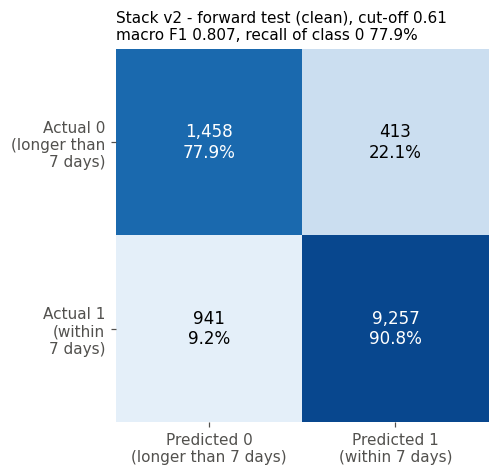

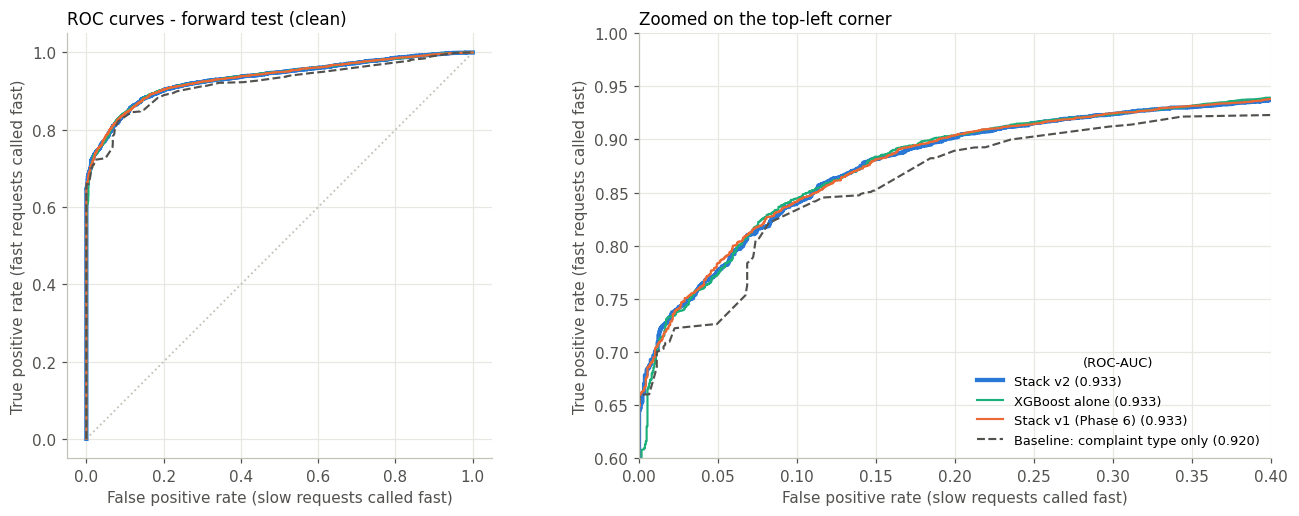

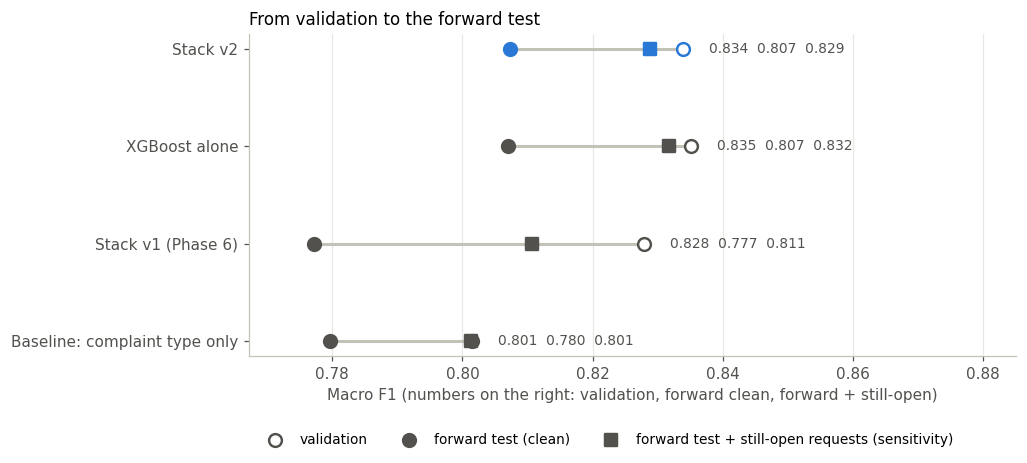

In [4]:
row = clean.loc["Stack v2"]
fig, ax = plt.subplots(figsize=(5.2, 4.4))
counts = np.array([[row["actual0_pred0"], row["actual0_pred1"]], [row["actual1_pred0"], row["actual1_pred1"]]], dtype=float)
shares = counts / counts.sum(axis=1, keepdims=True)
ax.imshow(shares, cmap="Blues", vmin=0, vmax=1)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{int(counts[i, j]):,}\n{shares[i, j]:.1%}", ha="center", va="center", fontsize=11,
                color="white" if shares[i, j] > 0.55 else "black")
ax.set_xticks([0, 1], ["Predicted 0\n(longer than 7 days)", "Predicted 1\n(within 7 days)"])
ax.set_yticks([0, 1], ["Actual 0\n(longer than\n7 days)", "Actual 1\n(within\n7 days)"])
ax.set_title(f"Stack v2 - forward test (clean), cut-off {threshold}\nmacro F1 {row['macro_f1']:.3f}, recall of class 0 {row['recall_0']:.1%}", loc="left", fontsize=10)
ax.grid(False)
for side_ in ax.spines.values():
    side_.set_visible(False)
fig.savefig(FIG_DIR / "07_forward_confusion_stack_v2.png")
plt.show()

colors = {"Stack v2": BLUE, "XGBoost alone": AQUA, "Stack v1 (Phase 6)": ORANGE, "Baseline: complaint type only": INK}
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
for ax, zoom in zip(axes, [False, True]):
    ax.plot([0, 1], [0, 1], color=GREY, linewidth=1.2, linestyle=":")
    for name, color in colors.items():
        fpr, tpr, _ = roc_curve(scores["y"], scores[name])
        ax.plot(fpr, tpr, color=color, linewidth=2.8 if name == "Stack v2" else 1.4, linestyle="--" if name.startswith("Baseline") else "-",
                label=f"{name} ({clean.loc[name, 'roc_auc']:.3f})")
    ax.set_xlabel("False positive rate (slow requests called fast)")
    ax.set_ylabel("True positive rate (fast requests called fast)")
    if zoom:
        ax.set_xlim(0, 0.4)
        ax.set_ylim(0.6, 1.0)
        ax.set_title("Zoomed on the top-left corner", loc="left", fontsize=11)
        ax.legend(loc="lower right", frameon=False, fontsize=8.5, title="(ROC-AUC)", title_fontsize=8.5)
    else:
        ax.set_title("ROC curves - forward test (clean)", loc="left", fontsize=11)
        ax.set_aspect("equal")
fig.tight_layout()
fig.savefig(FIG_DIR / "07_forward_roc_curves.png")
plt.show()

order = ["Baseline: complaint type only", "Stack v1 (Phase 6)", "XGBoost alone", "Stack v2"]
sets = [("validation", "o", "white"), (CLEAN, "o", None), (WITH_OPEN, "s", None)]
fig, ax = plt.subplots(figsize=(9, 3.8))
for i, name in enumerate(order):
    color = BLUE if name == "Stack v2" else INK
    values = [side.loc[name, s] for s, _, _ in sets]
    ax.plot([min(values), max(values)], [i, i], color=GREY, linewidth=2, zorder=1)
    for (s, marker, face), value in zip(sets, values):
        ax.scatter(value, i, marker=marker, s=70, zorder=3, color=face or color, edgecolor=color, linewidth=1.6,
                   label=s if i == 0 else None)
    ax.text(max(values) + 0.004, i, "  ".join(f"{v:.3f}" for v in values), va="center", fontsize=9, color=INK)
ax.set_yticks(range(len(order)), order)
ax.set_xlim(min(side[[s for s, _, _ in sets]].min()) - 0.01, max(side[[s for s, _, _ in sets]].max()) + 0.05)
ax.set_xlabel("Macro F1 (numbers on the right: validation, forward clean, forward + still-open)")
ax.set_title("From validation to the forward test", loc="left", fontsize=11)
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.2), ncols=3, frameon=False, fontsize=9)
ax.grid(axis="y", visible=False)
fig.savefig(FIG_DIR / "07_validation_vs_forward.png")
plt.show()

In [5]:
metric_keys = ["accuracy", "precision_0", "recall_0", "f1_0", "precision_1", "recall_1", "f1_1", "macro_f1", "roc_auc",
               "actual0_pred0", "actual0_pred1", "actual1_pred0", "actual1_pred1"]
as_dict = lambda r: {"requests": int(r["requests"]), **{k: (int(r[k]) if k.startswith("actual") else round(float(r[k]), 6)) for k in metric_keys}}
pick = lambda test_set, name: results[(results["test_set"] == test_set) & (results["model"] == name)].iloc[0]
metrics = json.loads(Path("../models/metrics.json").read_text())
metrics["forward_test"] = {**as_dict(pick(CLEAN, "Stack v2")),
                           "note": "the clean test: closed requests created 2026-09-01 to 2026-10-28, scored once, never used to choose anything"}
metrics["forward_test_with_still_open_requests"] = {**as_dict(pick(WITH_OPEN, "Stack v2")),
                                                    "note": "sensitivity: the forward test plus the still-open requests of the same period, counted as class 0"}
metrics["original_test_reused_optimistic"] = {**as_dict(pick(REUSED, "Stack v2")),
                                              "note": "NOT clean: this split was seen in Phase 6 before the stack was improved"}
metrics["validation_to_forward_gap_points"] = {k: round((float(pick(CLEAN, "Stack v2")[k]) - float(validation.loc["Stack v2", k])) * 100, 3)
                                               for k in ["accuracy", "precision_0", "recall_0", "f1_0", "macro_f1", "roc_auc"]}
metrics["xgboost_alone"].update({"forward_test_macro_f1": round(float(pick(CLEAN, "XGBoost alone")["macro_f1"]), 6),
                                 "forward_test_roc_auc": round(float(pick(CLEAN, "XGBoost alone")["roc_auc"]), 6)})
metrics["version_1"]["forward_test"] = as_dict(pick(CLEAN, "Stack v1 (Phase 6)"))
Path("../models/metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
print("Updated ../models/metrics.json with the forward test results.")
print(json.dumps({k: metrics[k] for k in ["validation_to_forward_gap_points"]}, indent=2))

Updated ../models/metrics.json with the forward test results.
{
  "validation_to_forward_gap_points": {
    "accuracy": -1.497,
    "precision_0": -7.987,
    "recall_0": 0.814,
    "f1_0": -4.408,
    "macro_f1": -2.654,
    "roc_auc": -1.064
  }
}


**Summary of Phase 6b.**

- **Diagnosis.** The Phase 6 gap between the stack and XGBoost was almost entirely the decision threshold: 0.73 points at the cut-off 0.5, 0.08 points when each model's cut-off is chosen on the training rows.
- **Experiments.** Seven stacks were tried. All landed within 0.3 points of each other on validation. The winner by the pre-set rule is XGBoost + Logistic Regression + Bernoulli Naive Bayes + Random Forest, with a Logistic Regression final estimator without class weights and a cut-off of 0.61.
- **Success criterion: not met.** On validation the winner is 0.12 points of macro F1 below XGBoost alone (ROC-AUC +0.01). It is deployed anyway, because a stacking classifier is a course requirement.
- **Clean result.** On the forward test set the v2 stack and XGBoost alone are level (macro F1 0.8074 against 0.8070; ROC-AUC 0.9327 against 0.9330), and the v2 stack is 3.0 points of macro F1 above the Phase 6 stack. **The stack matches XGBoost alone; it does not beat it.**

**Which test numbers are clean.**

| Numbers | Status |
| --- | --- |
| Forward test, `reports/test_forward_results.csv`, rows "forward test (clean)" | **Clean.** Scored once, after everything was fixed and committed. Use these in the report. Note that the set contains closed requests only. |
| Forward test + still-open requests | Clean, but a sensitivity check: the label of the added requests is certain, the sampling differs from the training data. |
| Old test split, v1 results in `reports/test_results.csv` | Clean for the **v1** model: it was scored once, before any of this. |
| Old test split, v2 stack ("reused, optimistic") | **Not clean.** The decision to improve the stack was made after seeing this split. |
| Validation scores of the v2 stack | Slightly optimistic: the best of seven experiments was picked on this split. |

The forward test set is now used up too: do not use it to choose anything.